# CNN de deteccion de danos v4

Cambio respecto de `parte3/cnn_damage_detection_training3.ipynb`:

**Interiores reales sanos.** Se suman a las undamaged dos fuentes nuevas, dentro de `undamaged_superficies`:
- `interiores`: fotos reales de ambientes completos (habitaciones, oficinas, pasillos, cocinas, banos), de Open Images, licencia CC BY.
- `interiores_cerca`: recortes de cerca de esas mismas fotos (paredes, puertas, muebles).

Motivo: el modelo v3 marca dano en el 54,5 % de 200 fotos reales de interiores sanos, y en el 70 % de las capturas
sanas del simulador. Casi no habia visto ambientes interiores sanos: sus undamaged eran fachadas y superficies de hormigon de cerca.

Todo lo demas es igual a la v3: misma CNN de 4 bloques desde cero, label smoothing, calibracion con temperature
scaling y umbral elegido en validacion. Las fuentes de la v3 se separan igual que antes (mismo `random_state`),
asi que su conjunto de test es el mismo y las metricas son comparables. Las fuentes nuevas se separan por foto:
una foto y sus recortes van siempre al mismo conjunto, para que el test no tenga pedazos de fotos vistas en train.

Como el cupo de damaged es igual a la cantidad de undamaged, al sumar interiores tambien entran mas fotos con dano
(de deteccion y de clasificacion). No se usan datos sinteticos.

No pisa los modelos anteriores: guarda en `models/modelo_detection4.keras` y `models/modelo_detection4_calibracion.json`.

Antes de correrlo: ver `LEEME_entrenamiento4.md` en esta carpeta.


In [1]:
# Celda 1: imports, seeds y configuracion
# Igual que la v3; solo cambian las rutas del modelo y FUENTES_NUEVAS.
# Diferencias de la v3 respecto de la v2:
#   - las undamaged son las de deteccion + las superficies sanas
#   - PROP_CLASIF sube a 0.45: como hay mas undamaged, el cupo de damaged
#     crece y las damaged de deteccion no alcanzan solas. Ademas, mas fotos
#     de dano de cerca (las de clasificacion) contra superficies sanas de
#     cerca obligan al modelo a mirar el dano y no el encuadre.
#   - LABEL_SMOOTHING: en vez de etiquetas 0/1 usa 0.025/0.975
# Etiquetas igual que antes: damaged = 0, undamaged = 1, asi la salida
# sigmoid sigue siendo la probabilidad de "undamaged" y el backend no cambia.

import os
import gc
import json
import hashlib
import random
import subprocess

import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

LOCAL_DATA_DIR = "../data"  # los datos quedan en notebooks/, fuera de parte3
BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_detection"

DATASET_CSV = "../data_clasificacion/dataset_final.csv"
PROP_CLASIF = 0.55  # subido: con interiores no alcanzan las damaged de deteccion (ver LEEME)
LABEL_SMOOTHING = 0.05

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

CLASS_NAMES = ["damaged", "undamaged"]
MODEL_PATH = "../../models/modelo_detection4.keras"
CALIB_PATH = "../../models/modelo_detection4_calibracion.json"
FUENTES_NUEVAS = ["interiores", "interiores_cerca"]  # carpetas nuevas dentro de undamaged_superficies
CONTINUAR = False  # True solo para retomar un entrenamiento que se corto (ver celda 11)

I0000 00:00:1794765095.563990   18585 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794765095.673700   18585 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794765097.833998   18585 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Celda 2: verificar que las imagenes de deteccion esten en disco
# Las baja descargar_datos_deteccion3.ipynb (correrlo antes, una sola
# vez). Aca solo se chequea que esten las tres carpetas.
# Depende de: LOCAL_DATA_DIR (celda 1)

for carpeta in ["damaged", "undamaged", "undamaged_superficies"]:
    if not os.path.isdir(f"{LOCAL_DATA_DIR}/{carpeta}") or not os.listdir(f"{LOCAL_DATA_DIR}/{carpeta}"):
        raise FileNotFoundError(f"Falta {LOCAL_DATA_DIR}/{carpeta}: correr antes descargar_datos_deteccion3.ipynb")

for fuente in FUENTES_NUEVAS:
    if not os.path.isdir(f"{LOCAL_DATA_DIR}/undamaged_superficies/{fuente}"):
        raise FileNotFoundError(f"Falta {LOCAL_DATA_DIR}/undamaged_superficies/{fuente}: descomprimir ahi paquete_interiores.zip (ver LEEME_entrenamiento4.md)")

for carpeta in ["damaged", "undamaged"]:
    print(f"{carpeta}: {len(os.listdir(f'{LOCAL_DATA_DIR}/{carpeta}'))}")
for fuente in sorted(os.listdir(f"{LOCAL_DATA_DIR}/undamaged_superficies")):
    print(f"undamaged_superficies/{fuente}: {len(os.listdir(f'{LOCAL_DATA_DIR}/undamaged_superficies/{fuente}'))}")

damaged: 11194
undamaged: 12981
undamaged_superficies/interiores: 1659
undamaged_superficies/interiores_cerca: 3318
undamaged_superficies/ozgenel_negative: 2500
undamaged_superficies/sdnet_uw: 2500


In [3]:
# Celda 3: verificar el dataset de clasificacion
# Igual que la v2: necesita dataset_final.csv (de cnn_damage_classification_build_dataset.ipynb).
# Depende de: DATASET_CSV (celda 1)

if not os.path.exists(DATASET_CSV):
    raise FileNotFoundError(f"No existe {DATASET_CSV}: correr antes descargar_datos_deteccion3.ipynb")

clasif_df = pd.read_csv(DATASET_CSV)
# las rutas del csv son relativas a notebooks/; este notebook esta en notebooks/parte3
clasif_df["image_path"] = "../" + clasif_df["image_path"]
no_estan = [r for r in clasif_df["image_path"] if not os.path.exists(r)]
if no_estan:
    raise FileNotFoundError(f"{len(no_estan)} de {len(clasif_df)} imagenes no estan en disco (ej: {no_estan[0]})")

print(f"Dataset de clasificacion OK: {len(clasif_df)} imagenes, todas en disco")

Dataset de clasificacion OK: 39497 imagenes, todas en disco


In [4]:
# Celda 4: imagenes de deteccion y superficies, split train/val/test (70/15/15)
# Las de deteccion se separan igual que en la v2 (mismo random_state), asi
# el test de deteccion es el mismo. Las superficies se separan aparte,
# estratificadas por fuente, y entran como "undamaged" con origen
# "superficies" y grupo = fuente (sdnet_uw, ozgenel_negative, propias).
# Las fuentes nuevas (interiores, interiores_cerca) se separan por foto.
# Calcula el md5 de cada archivo para no repetir fotos entre fuentes.
# Depende de: LOCAL_DATA_DIR, CLASS_NAMES, SEED (celda 1)

FORMATOS_OK = (".jpg", ".jpeg", ".png", ".gif", ".bmp")

def md5_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

filas = []
for clase in CLASS_NAMES:
    carpeta = f"{LOCAL_DATA_DIR}/{clase}"
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(FORMATOS_OK):
            filas.append({"image_path": f"{carpeta}/{archivo}", "clase": clase,
                          "origen": "deteccion", "grupo": f"{clase} (deteccion)"})
det_df = pd.DataFrame(filas)

det_train, det_resto = train_test_split(det_df, test_size=0.30, stratify=det_df["clase"], random_state=SEED)
det_val, det_test = train_test_split(det_resto, test_size=0.50, stratify=det_resto["clase"], random_state=SEED)
det_df["split"] = "train"
det_df.loc[det_val.index, "split"] = "val"
det_df.loc[det_test.index, "split"] = "test"

filas = []
base_sup = f"{LOCAL_DATA_DIR}/undamaged_superficies"
for fuente in sorted(os.listdir(base_sup)):
    for archivo in sorted(os.listdir(f"{base_sup}/{fuente}")):
        if archivo.lower().endswith(FORMATOS_OK):
            filas.append({"image_path": f"{base_sup}/{fuente}/{archivo}", "clase": "undamaged",
                          "origen": "superficies", "grupo": fuente})
todas_sup = pd.DataFrame(filas)

# fuentes de la v3: se separan exactamente igual que en la v3 (mismo test)
sup_df = todas_sup[~todas_sup["grupo"].isin(FUENTES_NUEVAS)].reset_index(drop=True)
s_train, s_resto = train_test_split(sup_df, test_size=0.30, stratify=sup_df["grupo"], random_state=SEED)
s_val, s_test = train_test_split(s_resto, test_size=0.50, stratify=s_resto["grupo"], random_state=SEED)
sup_df["split"] = "train"
sup_df.loc[s_val.index, "split"] = "val"
sup_df.loc[s_test.index, "split"] = "test"

# fuentes nuevas: se separan por foto, asi una foto y sus recortes quedan en el mismo conjunto
int_df = todas_sup[todas_sup["grupo"].isin(FUENTES_NUEVAS)].reset_index(drop=True)
int_df["foto"] = int_df["image_path"].map(lambda r: os.path.splitext(os.path.basename(r))[0].split("_c")[0])
fotos = sorted(int_df["foto"].unique())
f_train, f_resto = train_test_split(fotos, test_size=0.30, random_state=SEED)
f_val, f_test = train_test_split(f_resto, test_size=0.50, random_state=SEED)
int_df["split"] = "train"
int_df.loc[int_df["foto"].isin(f_val), "split"] = "val"
int_df.loc[int_df["foto"].isin(f_test), "split"] = "test"
sup_df = pd.concat([sup_df, int_df.drop(columns="foto")], ignore_index=True)

det_df = pd.concat([det_df, sup_df], ignore_index=True)
det_df["hash"] = det_df["image_path"].map(md5_archivo)
antes = len(det_df)
det_df = det_df.drop_duplicates("hash").reset_index(drop=True)
print(f"Duplicados exactos descartados: {antes - len(det_df)}\n")

print(pd.crosstab([det_df["clase"], det_df["origen"]], det_df["split"])[["train", "val", "test"]])

Duplicados exactos descartados: 62

split                  train   val  test
clase     origen                        
damaged   deteccion     7834  1679  1679
undamaged deteccion     9043  1935  1942
          superficies   6983  1497  1497


In [5]:
# Celda 5: cuantas imagenes damaged se toman de cada fuente
# Igual que la v2: en cada split, cupo de damaged = cantidad de undamaged
# (ahora incluye las superficies). PROP_CLASIF de ese cupo sale de
# clasificacion y el resto de deteccion.
# Depende de: det_df (celda 4), PROP_CLASIF (celda 1)

SPLITS = ["train", "val", "test"]

cupos = pd.DataFrame(index=SPLITS)
cupos["undamaged"] = det_df[det_df["clase"] == "undamaged"]["split"].value_counts().reindex(SPLITS)
cupos["damaged_clasif"] = (cupos["undamaged"] * PROP_CLASIF).round().astype(int)
cupos["damaged_deteccion"] = cupos["undamaged"] - cupos["damaged_clasif"]
cupos["deteccion_disponibles"] = det_df[det_df["clase"] == "damaged"]["split"].value_counts().reindex(SPLITS)

faltan = cupos[cupos["damaged_deteccion"] > cupos["deteccion_disponibles"]]
if not faltan.empty:
    raise ValueError(f"No alcanzan las damaged de deteccion en {list(faltan.index)}: subir PROP_CLASIF")

print(cupos)

       undamaged  damaged_clasif  damaged_deteccion  deteccion_disponibles
train      16026            8814               7212                   7834
val         3432            1888               1544                   1679
test        3439            1891               1548                   1679


In [6]:
# Celda 6: imagenes de clasificacion que se agregan como damaged
# Igual que la v2: rearma el split del clasificador (mismo csv y
# random_state=42) para que el test de un modelo nunca este en el train del otro.
# Depende de: clasif_df (celda 3), det_df (celda 4), cupos (celda 5), SEED

c_train, c_resto = train_test_split(clasif_df, test_size=0.30, stratify=clasif_df["label"], random_state=42)
c_val, c_test = train_test_split(c_resto, test_size=0.50, stratify=c_resto["label"], random_state=42)

hashes_deteccion = set(det_df["hash"])
partes = []
for split, parte in zip(SPLITS, [c_train, c_val, c_test]):
    n = cupos.loc[split, "damaged_clasif"]
    frac = min(1.0, n * 1.2 / len(parte))
    candidatas = parte.groupby("label", group_keys=False).sample(frac=frac, random_state=SEED).copy()
    candidatas["hash"] = candidatas["image_path"].map(md5_archivo)
    repetidas = candidatas["hash"].isin(hashes_deteccion)
    candidatas = candidatas[~repetidas].drop_duplicates("hash")
    if len(candidatas) < n:
        raise ValueError(f"{split}: quedaron {len(candidatas)} imagenes de clasificacion y hacen falta {n}")
    muestra = candidatas.sample(n=n, random_state=SEED)
    print(f"{split}: {repetidas.sum()} candidatas descartadas por estar ya en deteccion, se toman {n}")
    partes.append(pd.DataFrame({
        "image_path": muestra["image_path"].values,
        "clase": "damaged",
        "origen": "clasificacion",
        "grupo": muestra["label"].values,
        "split": split,
    }))
extra_df = pd.concat(partes, ignore_index=True)
print(f"\nSe agregan {len(extra_df)} imagenes de clasificacion como damaged")

train: 1386 candidatas descartadas por estar ya en deteccion, se toman 8814


val: 299 candidatas descartadas por estar ya en deteccion, se toman 1888


test: 281 candidatas descartadas por estar ya en deteccion, se toman 1891

Se agregan 12593 imagenes de clasificacion como damaged


In [7]:
# Celda 7: dataset combinado y balanceado
# Todas las undamaged (deteccion + superficies) y, en cada split, la
# cantidad de damaged de deteccion que indica el cupo. Label: damaged = 0, undamaged = 1.
# Depende de: det_df (celda 4), cupos (celda 5), extra_df (celda 6)

det_usadas = [det_df[det_df["clase"] == "undamaged"]]
for split in SPLITS:
    disponibles = det_df[(det_df["clase"] == "damaged") & (det_df["split"] == split)]
    det_usadas.append(disponibles.sample(n=cupos.loc[split, "damaged_deteccion"], random_state=SEED))

todo_df = pd.concat(det_usadas + [extra_df], ignore_index=True).drop(columns="hash")
todo_df["label"] = todo_df["clase"].map({c: i for i, c in enumerate(CLASS_NAMES)})

train_df = todo_df[todo_df["split"] == "train"].reset_index(drop=True)
val_df = todo_df[todo_df["split"] == "val"].reset_index(drop=True)
test_df = todo_df[todo_df["split"] == "test"].reset_index(drop=True)

print(pd.crosstab([todo_df["clase"], todo_df["origen"]], todo_df["split"], margins=True)[SPLITS + ["All"]])

por_clase = pd.crosstab(todo_df["clase"], todo_df["split"])
assert (por_clase.loc["damaged"] == por_clase.loc["undamaged"]).all(), "damaged y undamaged no quedaron iguales"
print("\nOK: misma cantidad de damaged y undamaged en cada split")

split                    train   val  test    All
clase     origen                                 
damaged   clasificacion   8814  1888  1891  12593
          deteccion       7212  1544  1548  10304
undamaged deteccion       9043  1935  1942  12920
          superficies     6983  1497  1497   9977
All                      32052  6864  6878  45794

OK: misma cantidad de damaged y undamaged en cada split


In [8]:
# Celda 8: pipeline de imagenes con tf.data
# Igual que la v2. Las etiquetas van suavizadas solo en train
# (label smoothing): 0 -> LABEL_SMOOTHING/2 y 1 -> 1 - LABEL_SMOOTHING/2.
# En val y test quedan 0/1 para medir bien.
# Depende de: train_df, val_df, test_df (celda 7), IMG_SIZE, BATCH_SIZE, SEED

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_dataset(dataframe, training):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("float32").reshape(-1, 1)
    if training:
        labels = labels * (1 - LABEL_SMOOTHING) + LABEL_SMOOTHING / 2
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(dataframe), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)
print(f"train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

train: 32052 | val: 6864 | test: 6878


E0000 00:00:1794765184.311689   18585 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [9]:
# Celda 9: data augmentation
# Igual que la v2 mas brillo y traslacion: las capturas del robot cambian
# de iluminacion y de encuadre. Solo actua durante el entrenamiento.

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15, value_range=(0, 1)),
    layers.RandomTranslation(0.1, 0.1),
])

In [10]:
# Celda 10: arquitectura (crear el modelo desde cero)
# La misma CNN de la v2. Siempre se crea; si CONTINUAR = True, la celda 11
# la reemplaza por el ultimo modelo guardado.
# Depende de: data_augmentation (celda 9)

def build_cnn(input_shape=(224, 224, 3)):
    inputs = tf.keras.Input(shape=input_shape)
    x = layers.Rescaling(1./255)(inputs)
    x = data_augmentation(x)
    for filtros in [32, 64, 128, 256]:
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs)

model = build_cnn()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:
# Celda 11: retomar un entrenamiento cortado (solo si CONTINUAR = True)
# Normalmente no hace nada. Si el kernel se corto a mitad del
# entrenamiento, poner CONTINUAR = True en la celda 1 y volver a correr
# todo: aca se carga el ultimo modelo guardado y la celda 13 sigue desde ahi.

if CONTINUAR:
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Se retoma el entrenamiento desde {MODEL_PATH}")
else:
    print("Entrenamiento desde cero (CONTINUAR = False)")

Entrenamiento desde cero (CONTINUAR = False)


In [12]:
# Celda 12: callbacks
# Iguales a la v2: checkpoint con el menor val_loss y limpieza de memoria.

class MemoryCleanup(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", mode="min", save_best_only=True),
    MemoryCleanup()
]

In [13]:
# Celda 13: entrenamiento
# Se corre UNA sola vez. Entrena hasta 40 epocas y EarlyStopping lo corta
# solo cuando val_loss deja de mejorar durante 8 epocas seguidas, volviendo
# a los mejores pesos. El checkpoint guarda el mejor modelo en cada mejora.
# Solo si el kernel se llega a cortar: poner CONTINUAR = True en la celda 1
# y correr todo de nuevo; sigue desde el ultimo modelo guardado.

EPOCAS_MAX = 40
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_MAX, callbacks=callbacks)

Epoch 1/40


/home/johndoe/Escritorio/dev/pili/humanoid-damage-cnn/.venv/lib64/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


W0000 00:00:1794765188.677197   19448 cpu_allocator_impl.cc:82] Allocation of 23970816 exceeds 10% of free system memory.
W0000 00:00:1794765188.681409   19445 cpu_allocator_impl.cc:82] Allocation of 45163008 exceeds 10% of free system memory.
W0000 00:00:1794765188.679186   19450 cpu_allocator_impl.cc:82] Allocation of 23970816 exceeds 10% of free system memory.
W0000 00:00:1794765188.684206   19444 cpu_allocator_impl.cc:82] Allocation of 36499968 exceeds 10% of free system memory.
W0000 00:00:1794765188.699156   19447 cpu_allocator_impl.cc:82] Allocation of 36578304 exceeds 10% of free system memory.


   1/2004 ━━━━━━━━━━━━━━━━━━━━ 2:57:09 5s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.7965

   2/2004 ━━━━━━━━━━━━━━━━━━━━ 37:54 1s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.1476  

   3/2004 ━━━━━━━━━━━━━━━━━━━━ 37:05 1s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.1091

... (38,125 outputs left out)

2003/2004 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2371

2004/2004 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2371

Invalid SOS parameters for sequential JPEG


2004/2004 ━━━━━━━━━━━━━━━━━━━━ 3228s 2s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2371 - val_accuracy: 0.9046 - val_auc: 0.9755 - val_loss: 0.2281 - learning_rate: 2.5000e-04


In [14]:
# Celda 14: calibracion y umbral (sobre VALIDACION)
# 1. Temperature scaling: pasa la salida a logit, la divide por una
#    temperatura T y vuelve a sigmoid. T > 1 "afloja" las probabilidades
#    (menos 0 % y 100 %), T < 1 las "aprieta". Se elige la T que minimiza
#    la log-loss en validacion. No cambia el orden de las predicciones.
# 2. Umbral: en vez de 0.5 fijo, se elige el umbral de P(dano) que da el
#    mejor F1 para la clase damaged en validacion, ya con las
#    probabilidades calibradas.
# Se guarda todo en CALIB_PATH; el backend lo lee.
# Depende de: MODEL_PATH, val_ds, val_df

model = tf.keras.models.load_model(MODEL_PATH)

def a_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

val_p_undamaged = model.predict(val_ds, verbose=0).ravel()
val_y_damaged = (val_df["label"].values == 0).astype(int)
val_logit_damaged = -a_logit(val_p_undamaged)

temperaturas = np.arange(0.5, 6.01, 0.05)
perdidas = [log_loss(val_y_damaged, sigmoid(val_logit_damaged / t)) for t in temperaturas]
T = float(temperaturas[int(np.argmin(perdidas))])

val_p_damaged = sigmoid(val_logit_damaged / T)
umbrales = np.arange(0.20, 0.81, 0.01)
f1s = [f1_score(val_y_damaged, (val_p_damaged >= u).astype(int)) for u in umbrales]
UMBRAL = float(umbrales[int(np.argmax(f1s))])

with open(CALIB_PATH, "w") as f:
    json.dump({"temperatura": round(T, 3), "umbral_dano": round(UMBRAL, 3),
               "salida_modelo": "probabilidad de undamaged"}, f, indent=2)

print(f"Temperatura: {T:.2f} | umbral de dano: {UMBRAL:.2f} | guardado en {CALIB_PATH}")

Invalid SOS parameters for sequential JPEG


Temperatura: 0.90 | umbral de dano: 0.58 | guardado en ../../models/modelo_detection4_calibracion.json


Invalid SOS parameters for sequential JPEG


              precision    recall  f1-score   support

     damaged       0.93      0.92      0.92      3439
   undamaged       0.92      0.93      0.92      3439

    accuracy                           0.92      6878
   macro avg       0.92      0.92      0.92      6878
weighted avg       0.92      0.92      0.92      6878

ROC-AUC: 0.9783
ECE sin calibrar: 0.010 | calibrado: 0.009



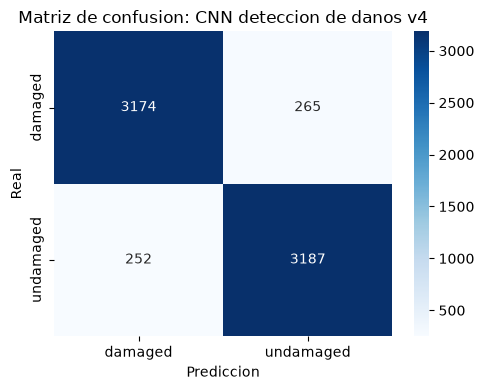

% de aciertos por grupo:
                                           imagenes  acierto
origen        grupo                                         
clasificacion Biological growth                  75     84.0
              Concrete spalling                  17     94.1
              Corrosion                         339     91.4
              Delamination                      145     97.9
              Material loss/erosion              76     98.7
              Moisture/water damage             198     93.9
              Salt weathering                   136     94.9
              Structural crack                  214     93.9
              Surface flaking/exfoliation       358     93.9
              Vandalism                          57     54.4
              Vegetation                        276     98.2
deteccion     damaged (deteccion)              1548     91.3
              undamaged (deteccion)            1942     96.0
superficies   interiores                        249     89.6

In [15]:
# Celda 15: evaluacion en test
# Usa las probabilidades calibradas y el umbral de la celda 14.
# Muestra:
#   - reporte por clase, matriz de confusion y ROC-AUC
#   - ECE (error de calibracion) antes y despues de calibrar: cuanto se
#     aleja el % que dice el modelo del % de aciertos real (mas bajo, mejor)
#   - % de aciertos por grupo: para superficies sanas es la proporcion que
#     el modelo reconoce como SIN dano (antes era casi 0 %)
# Depende de: model, test_ds, test_df, T, UMBRAL

def ece(y, p, bins=10):
    bordes = np.linspace(0, 1, bins + 1)
    conf = np.where(p >= 0.5, p, 1 - p)
    pred = (p >= 0.5).astype(int)
    total = 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.any():
            total += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return total

test_p_undamaged = model.predict(test_ds, verbose=0).ravel()
y_damaged = (test_df["label"].values == 0).astype(int)
p_damaged_crudo = 1 - test_p_undamaged
p_damaged = sigmoid(-a_logit(test_p_undamaged) / T)
pred_damaged = (p_damaged >= UMBRAL).astype(int)

y_true = 1 - y_damaged
y_pred = 1 - pred_damaged
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
print(f"ROC-AUC: {roc_auc_score(y_damaged, p_damaged):.4f}")
print(f"ECE sin calibrar: {ece(y_damaged, p_damaged_crudo):.3f} | calibrado: {ece(y_damaged, p_damaged):.3f}\n")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Matriz de confusion: CNN deteccion de danos v4")
plt.xlabel("Prediccion")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

res_df = test_df.assign(pred=np.array(CLASS_NAMES)[y_pred], prob_damaged=p_damaged)
res_df["acierto"] = res_df["pred"] == res_df["clase"]
por_grupo = res_df.groupby(["origen", "grupo"]).agg(imagenes=("acierto", "size"), acierto=("acierto", "mean"))
por_grupo["acierto"] = (por_grupo["acierto"] * 100).round(1)
print("% de aciertos por grupo:")
print(por_grupo.to_string())

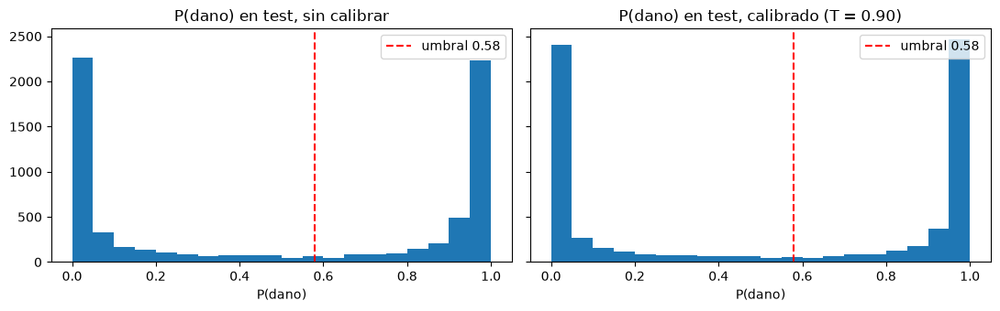

In [16]:
# Celda 16: histograma de confianza
# Compara cuantas predicciones caen en cada rango de P(dano) antes y
# despues de calibrar. Antes casi todo estaba pegado a 0 % o 100 %.

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, p, titulo in zip(axes, [p_damaged_crudo, p_damaged], ["sin calibrar", f"calibrado (T = {T:.2f})"]):
    ax.hist(p, bins=20, range=(0, 1))
    ax.axvline(UMBRAL, color="red", linestyle="--", label=f"umbral {UMBRAL:.2f}")
    ax.set_title(f"P(dano) en test, {titulo}")
    ax.set_xlabel("P(dano)")
    ax.legend()
plt.tight_layout()
plt.show()

In [17]:
# Celda 17: prueba con paredes lisas sinteticas y con la carpeta "prueba"
# Genera paredes lisas (blanca, beige, gris) que el modelo v2 marcaba con
# 100 % de dano, y predice tambien las imagenes de FOLDER_PATH.

FOLDER_PATH = "../prueba"
rng = np.random.default_rng(0)

def pared(base, ruido, grad):
    y = np.linspace(0, 1, 224)[:, None, None]
    img = np.ones((224, 224, 3)) * np.array(base) * (1 - grad * y)
    return np.clip(img + rng.normal(0, ruido, img.shape), 0, 255).astype("float32")

casos = {"pared blanca": pared((242, 242, 238), 2, 0.05), "pared blanca con sombra": pared((240, 240, 236), 3, 0.35),
         "pared beige": pared((222, 205, 180), 5, 0.10), "hormigon gris": pared((150, 150, 148), 12, 0.10)}
for archivo in sorted(f for f in os.listdir(FOLDER_PATH) if f.lower().endswith((".jpg", ".jpeg", ".png"))):
    img, _ = load_image(os.path.join(FOLDER_PATH, archivo), 0)
    casos[archivo] = img.numpy()

for nombre, img in casos.items():
    p_und = float(model.predict(img[None], verbose=0)[0][0])
    p_dan = float(sigmoid(-a_logit(np.array([p_und])) / T)[0])
    print(f"{nombre:30s} P(dano) calibrada: {p_dan:6.1%} -> {'CON dano' if p_dan >= UMBRAL else 'sin dano'}")

pared blanca                   P(dano) calibrada:   2.2% -> sin dano


pared blanca con sombra        P(dano) calibrada:   4.5% -> sin dano


pared beige                    P(dano) calibrada:  82.4% -> CON dano


hormigon gris                  P(dano) calibrada:  93.9% -> CON dano


000012.jpg                     P(dano) calibrada:  95.7% -> CON dano


00007.jpg                      P(dano) calibrada:  92.8% -> CON dano


00009.jpg                      P(dano) calibrada:  98.2% -> CON dano


00011.jpg                      P(dano) calibrada:  87.7% -> CON dano


frame_02400.png                P(dano) calibrada:  18.3% -> sin dano
